# Exploración 2: un rango en lugar de un número

El pronóstico de agosto es un único número. En esta notebook calculamos un **rango**: entre qué valores esperamos que quede la producción total, con 80 % de confianza.

Lo hacemos de dos maneras:

1. **Para el total del país**: repetimos el pronóstico mes a mes durante 19 meses (enero 2025 a julio 2026), cada vez con información anterior al mes, y medimos cuánto se equivocó. La distribución de esos errores da el rango.
2. **Para cada pozo**: entrenamos un modelo de *regresión por cuantiles* (`HistGradientBoostingRegressor` con pérdida cuantil) que predice directamente los percentiles 10, 50 y 90 de la producción de cada pozo.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comun import *

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.float_format", lambda valor: f"{valor:,.1f}")
plt.rcParams["figure.figsize"] = (11, 4.5)
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
panel, inferencia = cargar_panel()
produccion = cargar_produccion_pais()
resumen = resumen_pozos_nuevos(produccion)
print(f"Panel: {len(panel):,} filas, objetivos {panel['mes_objetivo'].min():%Y-%m} a {panel['mes_objetivo'].max():%Y-%m}")

Panel: 415,126 filas, objetivos 2006-02 a 2026-07


## 1. Pronóstico rodante mes a mes

Para cada mes objetivo entre enero de 2025 y julio de 2026:

- entrenamos el Random Forest de la notebook 04 con los 24 meses de objetivos anteriores;
- pronosticamos los pozos que producían el mes anterior;
- sumamos el aporte esperado de los pozos nuevos (exploración 1);
- comparamos con la producción real total del país.

Como referencia usamos la **persistencia**: suponer que el mes siguiente será igual al actual.

Esta celda entrena 19 modelos y tarda alrededor de media hora.

In [3]:
meses_objetivo = pd.date_range("2025-01-01", "2026-07-01", freq="MS")
rodante = backtest_rodante(panel, horizonte=1, meses_objetivo=meses_objetivo)

rodante["nuevos_pronostico_m3"] = [
    pronostico_pozos_nuevos(produccion, resumen, corte, horizonte=1)[0] for corte in rodante["mes_corte"]
]
rodante["total_real_m3"] = resumen.loc[rodante["mes_objetivo"], "total_pais_m3"].to_numpy()
rodante["total_mes_corte_m3"] = resumen.loc[rodante["mes_corte"], "total_pais_m3"].to_numpy()
rodante["total_pronostico_m3"] = rodante["pronostico_existentes_m3"] + rodante["nuevos_pronostico_m3"]

rodante["error_existentes_%"] = (rodante["pronostico_existentes_m3"] / rodante["real_existentes_m3"] - 1) * 100
rodante["error_total_%"] = (rodante["total_pronostico_m3"] / rodante["total_real_m3"] - 1) * 100
rodante["error_persistencia_%"] = (rodante["total_mes_corte_m3"] / rodante["total_real_m3"] - 1) * 100
rodante["acierta_direccion"] = (
    np.sign(rodante["total_pronostico_m3"] - rodante["total_mes_corte_m3"])
    == np.sign(rodante["total_real_m3"] - rodante["total_mes_corte_m3"])
)

rodante.to_csv(RUTA_RESULTADOS / "backtest_rodante_1_mes.csv", index=False)
display(rodante[["mes_objetivo", "total_real_m3", "total_pronostico_m3", "error_total_%",
                 "error_persistencia_%", "acierta_direccion"]])

Usando resultados guardados: rodante_h1_202501_202607_v24.csv


,mes_objetivo,total_real_m3,total_pronostico_m3,error_total_%,error_persistencia_%,acierta_direccion
0,2025-01-01,"2,208,382.0","2,198,168.8",-0.5,1.1,True
1,2025-02-01,"1,996,798.3","2,163,418.7",8.3,10.6,True
2,2025-03-01,"2,224,261.9","2,148,002.0",-3.4,-10.2,True
3,2025-04-01,"2,130,961.4","2,228,220.7",4.6,4.4,False
4,2025-05-01,"2,232,507.8","2,237,344.4",0.2,-4.5,True
5,2025-06-01,"2,295,205.1","2,292,571.3",-0.1,-2.7,True
6,2025-07-01,"2,531,393.3","2,451,307.7",-3.2,-9.3,True
7,2025-08-01,"2,619,162.7","2,533,563.7",-3.3,-3.4,True
8,2025-09-01,"2,631,180.9","2,639,225.0",0.3,-0.5,True
9,2025-10-01,"2,822,493.7","2,734,505.7",-3.1,-6.8,True


## 2. Cuánto se equivoca el pronóstico total

,Pozos existentes (modelo),Total con pozos nuevos (modelo),Total con persistencia
error absoluto medio %,2.9,3.0,5.1
error medio (sesgo) %,-0.1,-0.2,-1.7
percentil 10 %,-3.4,-3.3,-9.5
percentil 90 %,5.4,5.3,5.6
peor mes %,8.5,8.3,12.3


Meses en que acertó si la producción subía o bajaba: 16 de 19
Error medio por pozo: modelo 122.7 m³, persistencia 155.5 m³


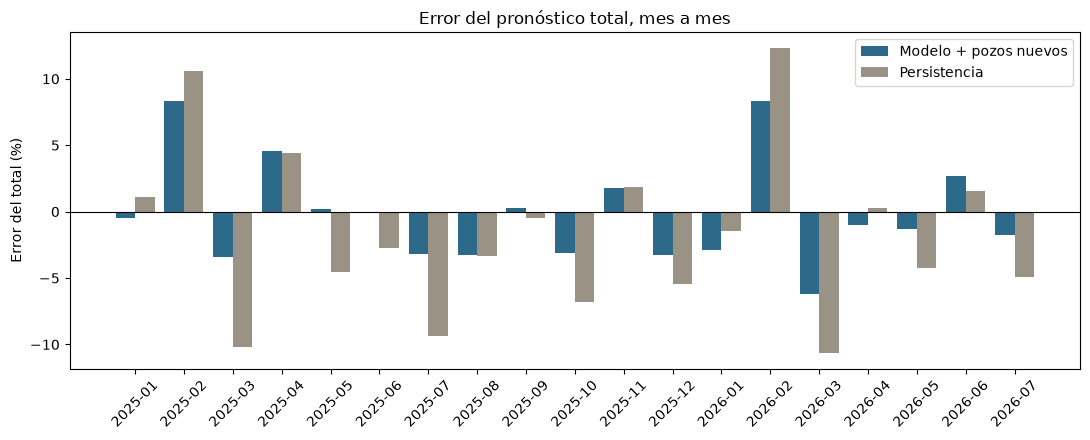

In [4]:
def describir_errores(errores):
    return pd.Series({
        "error absoluto medio %": errores.abs().mean(),
        "error medio (sesgo) %": errores.mean(),
        "percentil 10 %": errores.quantile(0.10),
        "percentil 90 %": errores.quantile(0.90),
        "peor mes %": errores.abs().max(),
    })

resumen_errores = pd.DataFrame({
    "Pozos existentes (modelo)": describir_errores(rodante["error_existentes_%"]),
    "Total con pozos nuevos (modelo)": describir_errores(rodante["error_total_%"]),
    "Total con persistencia": describir_errores(rodante["error_persistencia_%"]),
})
display(resumen_errores)
print(f"Meses en que acertó si la producción subía o bajaba: {rodante['acierta_direccion'].sum()} de {len(rodante)}")
print(f"Error medio por pozo: modelo {rodante['mae_modelo'].mean():.1f} m³, persistencia {rodante['mae_persistencia'].mean():.1f} m³")

fig, eje = plt.subplots()
x = np.arange(len(rodante))
eje.bar(x - 0.2, rodante["error_total_%"], width=0.4, label="Modelo + pozos nuevos", color="#2D6A8A")
eje.bar(x + 0.2, rodante["error_persistencia_%"], width=0.4, label="Persistencia", color="#9A9284")
eje.axhline(0, color="black", linewidth=0.8)
eje.set_xticks(x, rodante["mes_objetivo"].dt.strftime("%Y-%m"), rotation=45)
eje.set_ylabel("Error del total (%)")
eje.set_title("Error del pronóstico total, mes a mes")
eje.legend()
plt.tight_layout()
plt.show()

## 3. Rango para agosto de 2026

Si el error del pronóstico es `pronóstico / real − 1`, el valor real es `pronóstico / (1 + error)`. Aplicando los percentiles 10 y 90 de los errores observados al pronóstico de agosto obtenemos un rango del 80 %.

In [5]:
agosto = pd.read_csv(RUTA_RESULTADOS / "agosto_con_pozos_nuevos.csv", index_col=0)
central = agosto.loc["Agosto: total", "m³"]
total_julio = agosto.loc["Julio 2026 (real, todos los pozos)", "m³"]

p10_error, p90_error = rodante["error_total_%"].quantile([0.10, 0.90]) / 100
rango_agosto = pd.DataFrame({
    "m³": [central / (1 + p90_error), central, central / (1 + p10_error)],
}, index=["Escenario bajo (P10)", "Central", "Escenario alto (P90)"])
rango_agosto["vs julio %"] = (rango_agosto["m³"] / total_julio - 1) * 100
display(rango_agosto)
rango_agosto.to_csv(RUTA_RESULTADOS / "rango_agosto_2026.csv")

,m³,vs julio %
Escenario bajo (P10),"3,103,120.8",-3.0
Central,"3,268,211.8",2.2
Escenario alto (P90),"3,380,659.8",5.7


## 4. Rango por pozo: regresión por cuantiles

El rango anterior sirve para el total. Para cada pozo usamos un modelo que predice percentiles en lugar de un promedio: `HistGradientBoostingRegressor` con `loss="quantile"`. Entrenamos un modelo para el percentil 10, otro para el 50 y otro para el 90.

Si el modelo está bien calibrado, alrededor del 80 % de los valores reales debería caer entre el percentil 10 y el 90.

Entrenamos con objetivos de enero 2024 a diciembre 2025 y evaluamos en el test de la notebook 04 (abril a julio de 2026).

In [6]:
def crear_modelo_cuantil(cuantil):
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", FEATURES_NUMERICAS),
        ("categoricas", Pipeline([
            ("imputacion", SimpleImputer(strategy="constant", fill_value="Sin dato")),
            ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)),
        ]), FEATURES_CATEGORICAS),
    ])
    modelo = HistGradientBoostingRegressor(
        loss="quantile", quantile=cuantil, max_iter=400, learning_rate=0.05,
        min_samples_leaf=40, random_state=42,
    )
    return Pipeline([("preprocesamiento", preprocesamiento), ("modelo", modelo)])

entrenamiento_q = panel[panel["mes_objetivo"].between("2024-01-01", "2025-12-01")]
test_q = panel[panel["mes_objetivo"].between("2026-04-01", "2026-07-01")]
cuantiles = {"p10": 0.10, "p50": 0.50, "p90": 0.90}

predicciones_q = pd.DataFrame(index=test_q.index)
for nombre, cuantil in cuantiles.items():
    modelo = crear_modelo_cuantil(cuantil).fit(entrenamiento_q[FEATURES], entrenamiento_q[OBJETIVO])
    predicciones_q[nombre] = np.clip(modelo.predict(test_q[FEATURES]), 0, None)
# Los modelos se entrenan por separado; ordenamos para que p10 <= p50 <= p90.
predicciones_q[:] = np.sort(predicciones_q.to_numpy(), axis=1)

real_q = test_q[OBJETIVO]
dentro = (real_q >= predicciones_q["p10"]) & (real_q <= predicciones_q["p90"])
produce = test_q["prod_pet"] > 0

cobertura = pd.DataFrame({
    "pozos-mes": [len(test_q), produce.sum(), (~produce).sum()],
    "real dentro del rango %": [dentro.mean() * 100, dentro[produce].mean() * 100, dentro[~produce].mean() * 100],
    "ancho medio del rango (m³)": [
        (predicciones_q["p90"] - predicciones_q["p10"]).mean(),
        (predicciones_q["p90"] - predicciones_q["p10"])[produce].mean(),
        (predicciones_q["p90"] - predicciones_q["p10"])[~produce].mean(),
    ],
    "error medio de la mediana (m³)": [
        (predicciones_q["p50"] - real_q).abs().mean(),
        (predicciones_q["p50"] - real_q)[produce].abs().mean(),
        (predicciones_q["p50"] - real_q)[~produce].abs().mean(),
    ],
}, index=["Todos", "Producía en el mes de corte", "No producía en el mes de corte"])
display(cobertura)

,pozos-mes,real dentro del rango %,ancho medio del rango (m³),error medio de la mediana (m³)
Todos,19737,89.1,503.9,134.1
Producía en el mes de corte,13834,86.5,700.9,185.5
No producía en el mes de corte,5903,95.2,42.1,13.6


Para agosto reentrenamos los tres modelos con los 24 meses que terminan en julio de 2026 y guardamos el rango de cada pozo. Mostramos los diez pozos con mayor producción en julio.

In [7]:
entrenamiento_q_inferencia = panel[panel["mes_objetivo"].between("2024-08-01", "2026-07-01")]
rangos_pozo = inferencia[["idpozo", "sigla", "empresa", "prod_pet"]].copy()
for nombre, cuantil in cuantiles.items():
    modelo = crear_modelo_cuantil(cuantil).fit(entrenamiento_q_inferencia[FEATURES], entrenamiento_q_inferencia[OBJETIVO])
    rangos_pozo[nombre] = np.clip(modelo.predict(inferencia[FEATURES]), 0, None)
rangos_pozo[list(cuantiles)] = np.sort(rangos_pozo[list(cuantiles)].to_numpy(), axis=1)
rangos_pozo = rangos_pozo.rename(columns={"prod_pet": "julio_real_m3"})

rangos_pozo.to_csv(RUTA_RESULTADOS / "rango_por_pozo_agosto_2026.csv", index=False)
display(rangos_pozo.sort_values("julio_real_m3", ascending=False).head(10))

,idpozo,sigla,empresa,julio_real_m3,p10,p50,p90
4978,167344,PCN.Nq.BdC-1128(h),PLUSPETROL CUENCA NEUQUINA S.R.L.,"13,646.6",173.9,"8,618.5","11,205.9"
4910,167258,PCN.Nq.BdC-1126(h),PLUSPETROL CUENCA NEUQUINA S.R.L.,"13,164.9",173.9,"8,716.9","11,587.4"
4824,167141,YPF.Nq.LLL-1825(h),YPF S.A.,"11,414.8",93.8,"8,196.7","9,548.1"
4857,167186,PCN.Nq.BdC-1011(h),PLUSPETROL CUENCA NEUQUINA S.R.L.,"11,314.9",93.8,"8,353.6","11,210.4"
4854,167183,PCN.Nq.BdC-1008(h),PLUSPETROL CUENCA NEUQUINA S.R.L.,"11,301.4",93.8,"8,038.2","11,169.4"
4908,167256,PCN.Nq.BdC-1015(h)(I),PLUSPETROL CUENCA NEUQUINA S.R.L.,"11,207.7",173.9,"8,204.7","10,731.5"
4903,167249,VIS.Nq.BPE-2323(h),VISTA ENERGY ARGENTINA SAU,"11,099.2",173.9,"7,474.9","8,431.4"
4902,167248,VIS.Nq.BPE-2322(h),VISTA ENERGY ARGENTINA SAU,"10,953.2",173.9,"7,543.9","8,812.7"
4670,166911,PCN.Nq.BdC-1001(h),PLUSPETROL CUENCA NEUQUINA S.R.L.,"10,583.3",93.8,"7,793.2","10,695.5"
4953,167317,YPF.Nq.LACh-560(h),YPF S.A.,"10,580.4",173.9,"8,305.4","10,476.5"


## Conclusiones

- **Error típico del total: 3 % por mes.** En 19 meses de pronóstico rodante (enero 2025 a julio 2026), el total con pozos nuevos se desvió en promedio 3,0 %, sin sesgo (−0,2 %). La persistencia se desvió 5,1 %. Acertó si la producción subía o bajaba en 16 de los 19 meses.
- **Febrero y marzo explican buena parte del error.** El modelo no ajusta por la cantidad de días del mes: sobreestima febrero (+8 %) y subestima marzo (−3 % a −6 %). Sin esos meses el error medio baja a 2,0 %. Pronosticar producción por día y multiplicar por los días del mes es una mejora barata pendiente.
- **La prueba de abril a julio de la notebook 04 fue un período tranquilo** (1,5 % de error). El 3 % de esta notebook es una medida más representativa.
- **Rango del 80 % para agosto de 2026:** entre 3,10 y 3,38 millones de m³, es decir entre −3,0 % y +5,7 % respecto de julio, con un valor central de 3,27 millones (+2,2 %). La suba es lo más probable, pero una baja leve no se puede descartar.
- **Rango por pozo:** la regresión por cuantiles dejó el valor real dentro del rango en el 89 % de los casos (se buscaba 80 %), así que sus rangos son algo más anchos de lo necesario. El ancho medio para un pozo que produce es de unos 700 m³. Los rangos por pozo no se pueden sumar para obtener el rango del total, porque los errores de los pozos no son independientes.